# 🌙 Day 17 · Light & dark: Uzbekistan at night

**#30DayMapChallenge Uzbekistan 2026** · beginner tutorial, no experience needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NodiraTillayeva/30DayMapChallengeUzbekistan/blob/main/2026/Day%2017%20Light%20and%20Dark/tutorial/day17_night_lights.ipynb)

Every night a NASA satellite photographs the Earth in the dark. Cities, roads and villages glow; deserts and mountains stay black. Today you make a map with **nothing but light**.

In this notebook you will:
1. map Uzbekistan at night in 2025,
2. compare two years side by side,
3. find the places that got brighter or darker,
4. measure how the lit area grew from 2012 to 2025,
5. compare the regions, zoom into Tashkent, and save a poster.

Run the cells from top to bottom: click a cell, then press **Shift + Enter**.

## Step 0 · Get ready

The data is **NASA Black Marble** (product *VNP46A4*): one picture per year of how much light comes up from the ground at night. We cut it to Uzbekistan and saved one file per year, **2012 to 2025**. Each file is a **raster**: a grid of small squares (pixels, about 450 m wide), each with one number, its brightness.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, LinearSegmentedColormap
from urllib.request import urlretrieve

BASE = "https://raw.githubusercontent.com/NodiraTillayeva/30DayMapChallengeUzbekistan/main/2026/Day%2017%20Light%20and%20Dark/tutorial/data/"

YEARS = range(2012, 2026)
lights = {}
for year in YEARS:
    urlretrieve(BASE + f"lights_{year}.tif", f"lights_{year}.tif")
    with rasterio.open(f"lights_{year}.tif") as src:
        lights[year] = src.read(1)
        transform = src.transform
        b = src.bounds
extent = [b.left, b.right, b.bottom, b.top]

regions = gpd.read_file(BASE + "uzbekistan_regions.geojson")
print(f"Ready! ✅ {len(lights)} years, each {lights[2025].shape[1]} × {lights[2025].shape[0]} pixels")

Ready! ✅ 14 years, each 4152 × 2040 pixels


## Step 1 · Uzbekistan at night

The darkest pixels are **0**, city centres are **50 or more**, and a few gas flares are in the thousands. If we coloured them in a straight line, everything except one flare would be black. `PowerNorm(0.4)` stretches the dim values so villages show up too, and every pixel above `brightest=40` is shown as pure white.

Our colours go from black, through purple and orange, to white, like real night lights.

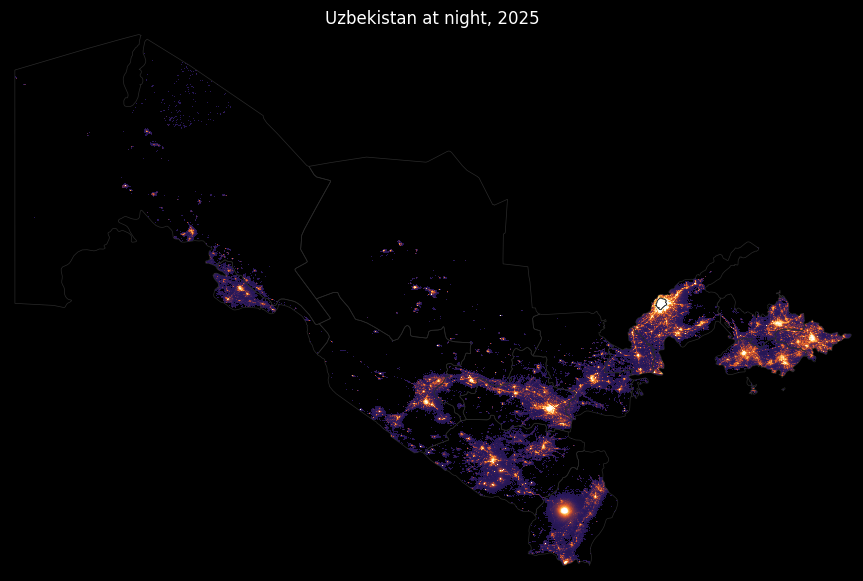

In [2]:
night = LinearSegmentedColormap.from_list("night", ["#000000", "#2b1a5e", "#d9572b", "#ffb347", "#fff6d5", "#ffffff"])
def night_map(year, ax, brightest=40):
    ax.set_facecolor("black")
    regions.boundary.plot(ax=ax, color="#2a2a2a", linewidth=0.5)
    L = lights[year]
    ax.imshow(np.where(L < 0.3, np.nan, L), cmap=night, norm=PowerNorm(0.4, vmin=0, vmax=brightest), extent=extent, interpolation="nearest")
    ax.set_aspect(1.3) 
    ax.axis("off")

fig, ax = plt.subplots(figsize=(12, 7), facecolor="black")
night_map(2025, ax)
ax.set_title("Uzbekistan at night, 2025", color="white")
plt.show()

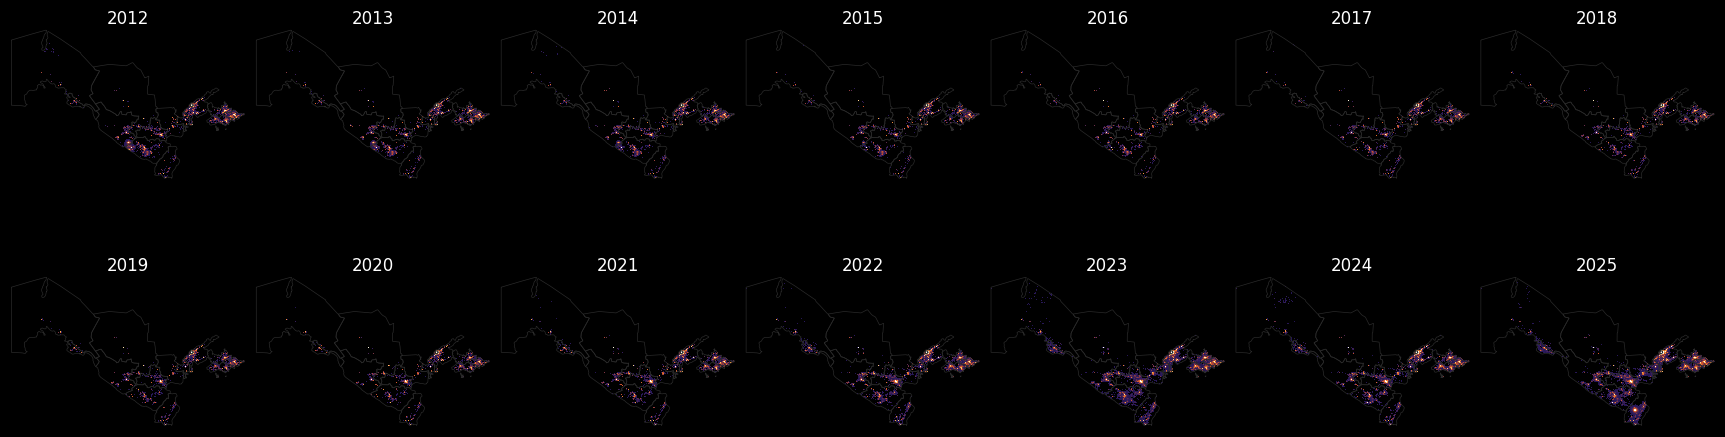

Saved flipbook to Downloads\uzbekistan_night_flipbook.png! ✅


In [4]:
fig, axes = plt.subplots(2, 7, figsize=(22, 6), facecolor="black")

for ax, year in zip(axes.flat, YEARS):
    night_map(year, ax)
    ax.set_title(str(year), color="white", fontsize=12, pad=4)

plt.subplots_adjust(wspace=0.04, hspace=0.15) 
plt.savefig(r"C:\Users\Asus\Downloads\uzbekistan_night_flipbook.png", dpi=300, facecolor="black", bbox_inches="tight")
plt.show()
print("Saved flipbook to Downloads\\uzbekistan_night_flipbook.png! ✅")


## Step 2 · Then and now

Change the two years to any years from 2012 to 2025. We start with **2016**, the darkest year in the data.

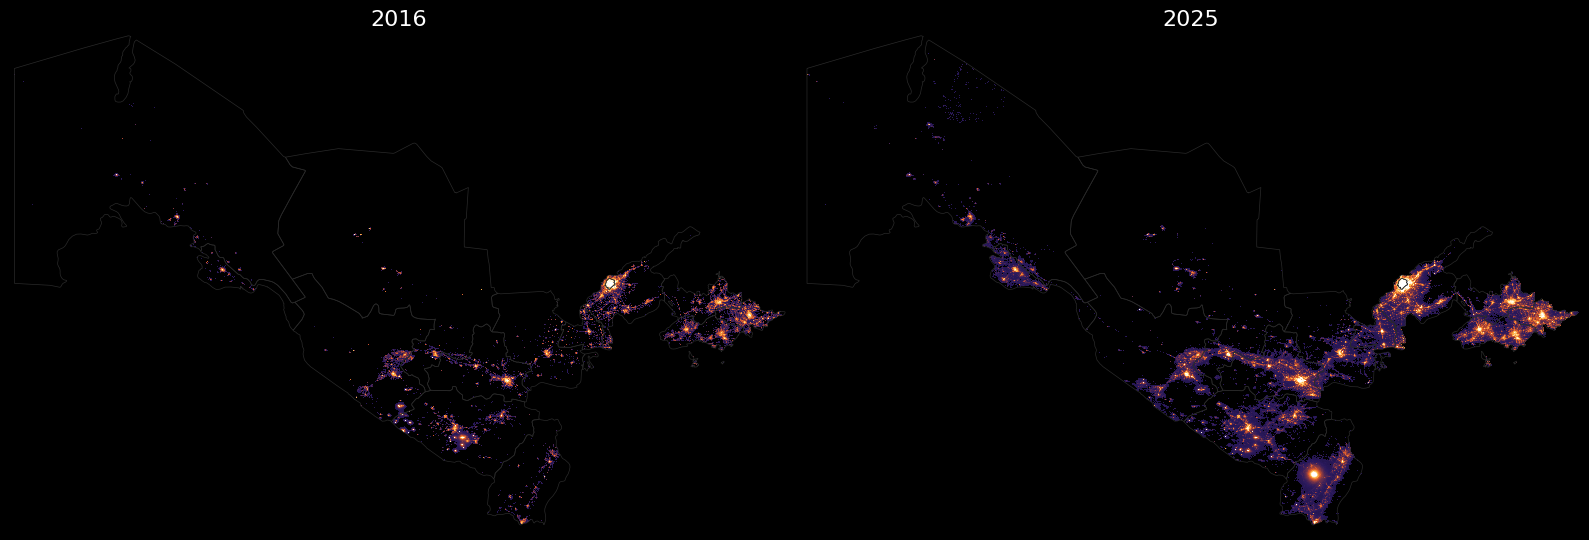

In [5]:
YEAR_A = 2016   # 👈 try other years
YEAR_B = 2025

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), facecolor="black")
for ax, year in zip(axes, [YEAR_A, YEAR_B]):
    night_map(year, ax)
    ax.set_title(year, color="white", fontsize=16)
plt.tight_layout() 
plt.show()

## Step 3 · What changed?

Subtract one year from the other, pixel by pixel. **Orange** = brighter in the later year, **blue** = darker, **black** = no change.

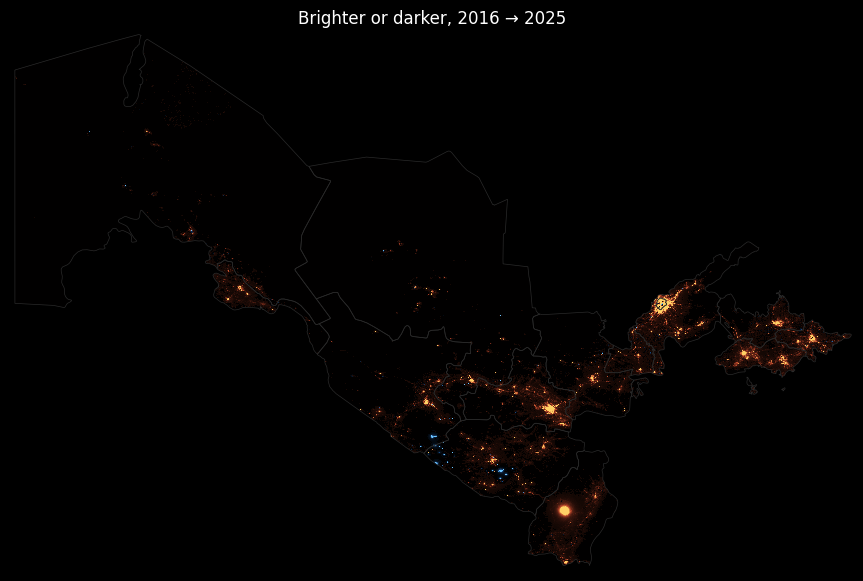

In [6]:
change = lights[YEAR_B] - lights[YEAR_A]
two_ways = LinearSegmentedColormap.from_list("two_ways", ["#6ec6ff", "#1d4e89", "#000000", "#b8452a", "#ffd166"])

fig, ax = plt.subplots(figsize=(12, 7), facecolor="black")
ax.set_facecolor("black")
regions.boundary.plot(ax=ax, color="#2a2a2a", linewidth=0.5)
ax.imshow(change, cmap=two_ways, vmin=-10, vmax=10, extent=extent, interpolation="nearest")
ax.set_aspect(1.3)
ax.axis("off")
ax.set_title(f"Brighter or darker, {YEAR_A} → {YEAR_B}", color="white")
plt.show()

## Step 4 · How much of the country is lit?

We count the pixels brighter than **1** in every year. One pixel is about **0.16 km²**, so pixels × 0.16 = lit area in km².

2012    18500
2013    16600
2014    15900
2015    14300
2016    13800
2017    14400
2018    13700
2019    14300
2020    14000
2021    17400
2022    21700
2023    25900
2024    21800
2025    30800
dtype: int64


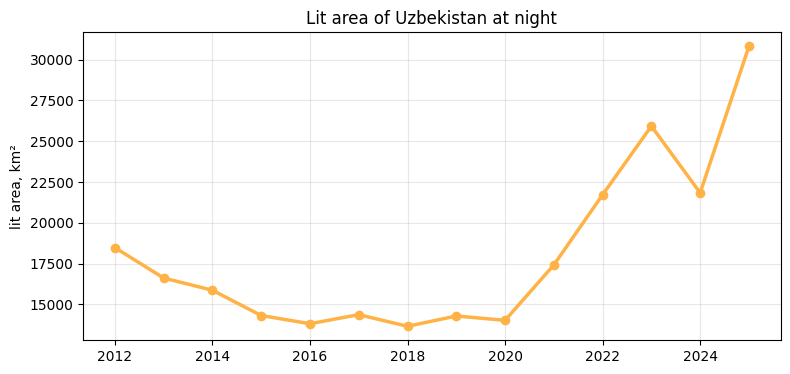

In [7]:
lit = pd.Series({year: (lights[year] > 1).sum() * 0.16 for year in YEARS})
print(lit.round(-2).astype(int))

ax = lit.plot(figsize=(9, 4), marker="o", color="#ffb347", linewidth=2.5)
ax.set_ylabel("lit area, km²")
ax.set_title("Lit area of Uzbekistan at night")
ax.grid(alpha=0.3)
plt.show()

## Step 5 · Which regions got brighter?

For each region we add up all its pixels in the two years. `geometry_mask` makes a True/False grid: True outside the region, False inside.

A **gas flare** (gas burning at an oil or gas field) can be brighter than a whole city. So before adding up, `np.minimum(..., 100)` lowers every pixel above 100 to 100. Try removing it and see how Surkhandarya jumps.

                  2016    2025  change %
region                                  
Tashkent City    45724   67133        47
Kashkadarya      69942  107420        54
Bukhoro          38160   62888        65
Andijon          41574   75887        83
Namangan         33863   63430        87
Tashkent Region  76046  178801       135
Navoi            15322   38568       152
Ferghana         33332   87708       163
Karakalpakstan    7799   20669       165
Sirdaryo         11627   32039       176
Jizzakh          14073   46585       231
Samarkand        29069  108813       274
Khorezm           4886   27991       473
Surkhandarya     13786  114149       728


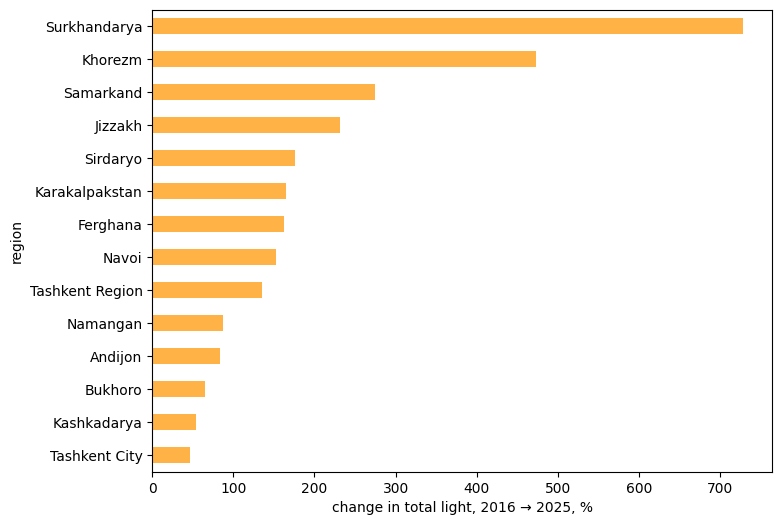

In [8]:
from rasterio.features import geometry_mask

rows = []
for _, r in regions.iterrows():
    outside = geometry_mask([r.geometry], lights[YEAR_A].shape, transform)
    a = np.nansum(np.minimum(lights[YEAR_A][~outside], 100))
    b = np.nansum(np.minimum(lights[YEAR_B][~outside], 100))
    rows.append({"region": r["region"], YEAR_A: round(a), YEAR_B: round(b), "change %": round((b - a) / a * 100)})

table = pd.DataFrame(rows).set_index("region").sort_values("change %")
print(table)

table["change %"].plot.barh(figsize=(8, 6), color="#ffb347")
plt.xlabel(f"change in total light, {YEAR_A} → {YEAR_B}, %") 
plt.show()

## Step 6 · Zoom into Tashkent

To zoom, we only change the edges of the map with `set_xlim` and `set_ylim` (longitude and latitude). The centre of Tashkent is much brighter than 40, so we raise `brightest` to 150; otherwise the whole city would be one white blob.

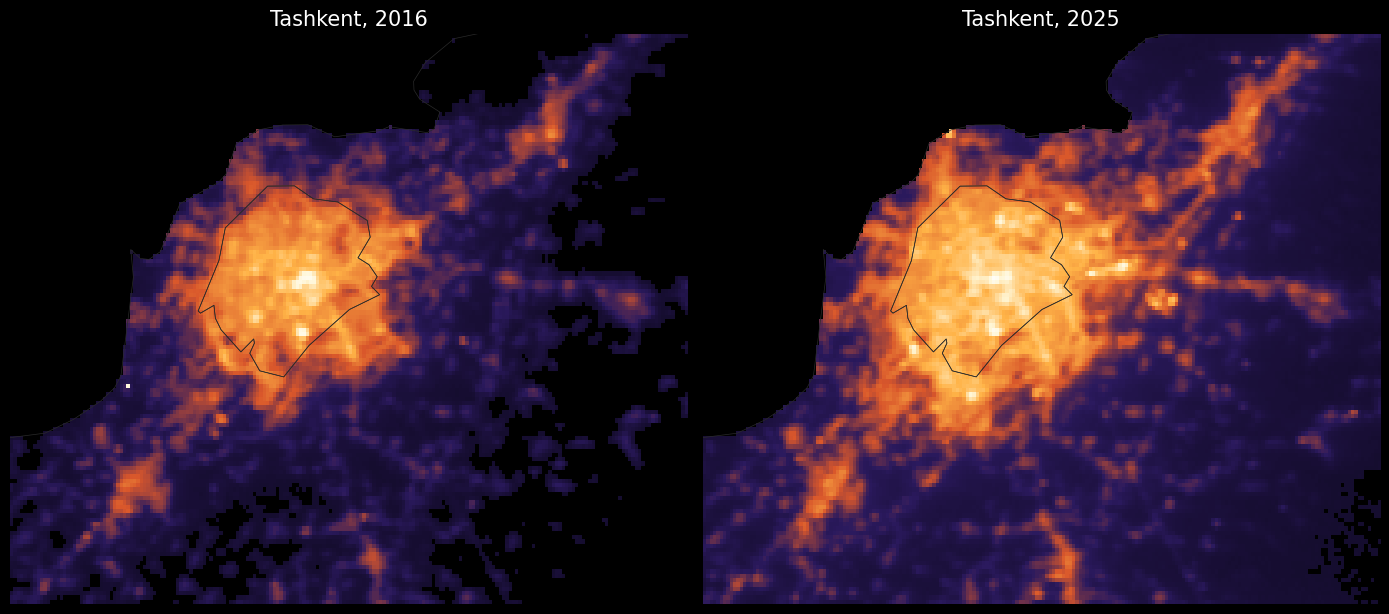

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), facecolor="black")
for ax, year in zip(axes, [YEAR_A, YEAR_B]):
    night_map(year, ax, brightest=150)
    ax.set_xlim(68.9, 69.75)
    ax.set_ylim(41.0, 41.55)
    ax.set_title(f"Tashkent, {year}", color="white", fontsize=15)
plt.tight_layout()
plt.show() 

## Step 7 · Save your poster

The 2025 map again, sharper (`dpi=300`), saved as **uzbekistan_at_night.png** and downloaded.

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7), facecolor="black")
night_map(2025, ax)
plt.savefig("uzbekistan_at_night.png", dpi=300, bbox_inches="tight", facecolor="black")

from google.colab import files
files.download("uzbekistan_at_night.png")

In [10]:
import io
from PIL import Image

frames = [] 
for year in YEARS:
    fig, ax = plt.subplots(figsize=(10, 6), facecolor="black")
    night_map(year, ax)
    ax.text(0.96, 0.05, str(year), transform=ax.transAxes,
            ha="right", va="bottom", color="white", fontsize=22, fontweight="bold")
    
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=130, facecolor="black", bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    frames.append(Image.open(buf).convert("P", palette=Image.ADAPTIVE))

# Hold 2025 slightly longer at the end (1.8 sec) while flipping other years at 0.55 sec
durations = [550] * (len(frames) - 1) + [1800]

frames[0].save(
    r"C:\Users\Asus\Downloads\uzbekistan_at_night.gif",
    save_all=True,
    append_images=frames[1:],
    duration=durations,
    loop=0
)
print("Saved animated GIF to Downloads\\uzbekistan_at_night.gif! ✅")


Saved animated GIF to Downloads\uzbekistan_at_night.gif! ✅


## Extra · Download Black Marble yourself

We prepared the files for you, but you can download any country and any year with **blackmarblepy**. You need a free **NASA Earthdata** account and a *token* (see the README). Each year is about 140 MB for every 10° × 10° square, so it takes a few minutes.

```python
!pip install -q blackmarblepy
from getpass import getpass
from blackmarble import BlackMarble, Product
import datetime as dt

TOKEN = getpass("Paste your NASA Earthdata token: ")
bm = BlackMarble(token=TOKEN, output_directory="h5")
area = regions[regions["region"] == "Khorezm"]          # 👈 a smaller area downloads faster
r = bm.raster(area, product_id=Product.VNP46A4, date_range=[dt.date(2025, 1, 1)])
r[list(r.data_vars)[0]].isel(time=0).plot(cmap="inferno", robust=True)
```